# Регресійна задача з однією змінною(ознакою):
# $y = wx + b$

# Множинна регресія(регресійна задача з кількома змінними):
# $y = w1x1 + w2x2 + ... + wnxn + b$


# Задача 1: Прогнозувати витрату палива автомобіля(літрів/100 км) за наступними параметрами:
* Об'єм двигуна(у літрах)
* Вага автомобіля(у кілограмах)
* Потужність двигуна (у кінських силах)

In [71]:
import numpy as np
import pandas as pd

In [72]:
cars_count = 300

In [141]:
engine_size = np.random.uniform(1.0, 5.0, cars_count)
weight = np.random.uniform(1000, 2500, cars_count)
horse_power = np.random.uniform(70, 350, cars_count)

In [142]:
fuel_consumption = (
    3.0 + (engine_size * 1.5) + (weight * 0.002) + (horse_power * 0.01) + np.random.normal(0, 1.5, size=cars_count)
)

In [143]:
df = pd.DataFrame({
    "EngineSize": engine_size,
    "Weight": weight,
    "HorsePower": horse_power,
    "FuelConsumption": fuel_consumption
})

df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,3.912380,1675.597049,283.498465,14.877922
1,2.849738,1622.276066,90.392736,10.509505
2,3.131526,2487.907141,127.805974,13.610931
3,1.270719,1701.996946,118.418641,9.339957
4,3.014369,1225.167471,290.914695,13.486296


In [146]:
df.loc[np.random.choice(cars_count, 15), 'Weight'] = np.nan
df.loc[np.random.choice(cars_count, 10), 'HorsePower'] = np.nan

In [77]:
df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,1.730117,1862.408185,140.989192,12.415654
1,4.232140,1284.156087,86.866112,13.463692
2,3.705630,1670.804577,339.078291,15.429093
3,3.727675,2118.873646,311.895759,15.766817
4,1.382195,1302.272254,337.988814,9.823924


In [147]:
df.loc[12, 'FuelConsumption'] = 45

In [148]:
df.loc[45, 'Weight'] = 12000.0

In [149]:
df.loc[88, 'EngineSize'] = -2.0

In [150]:
df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,3.912380,1675.597049,283.498465,14.877922
1,2.849738,1622.276066,90.392736,10.509505
2,3.131526,2487.907141,127.805974,13.610931
3,1.270719,1724.622799,118.418641,9.339957
4,3.014369,1225.167471,290.914695,13.486296


In [151]:
df = df[(df['EngineSize'] > 0) & (df['Weight'] < 6000)]

In [83]:
len(df)

284

In [84]:
from sklearn.impute import SimpleImputer

In [152]:
# замінює nan значеннями
imputer = SimpleImputer(strategy='median')
df[['EngineSize','Weight','HorsePower', 'FuelConsumption']] = imputer.fit_transform(
    df[['EngineSize','Weight','HorsePower', 'FuelConsumption']]
)

In [86]:
df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,1.730117,1862.408185,140.989192,12.415654
1,4.232140,1284.156087,86.866112,13.463692
2,3.705630,1670.804577,339.078291,15.429093
3,3.727675,2118.873646,311.895759,15.766817
4,1.382195,1302.272254,337.988814,9.823924


In [153]:
Q1 = df['FuelConsumption'].quantile(0.25)
Q3 = df['FuelConsumption'].quantile(0.75)
IQR = Q3 - Q1

In [154]:
df = df[(df['FuelConsumption'] >= Q1 - 1.5 *IQR) & (df['FuelConsumption'] <= Q3 + 1.5 * IQR)]

In [128]:
len(df)

283

In [127]:
df[df['FuelConsumption']>18]

,EngineSize,Weight,HorsePower,FuelConsumption
73,4.712373,2454.410822,335.648118,19.869711
74,4.961192,1404.041794,307.281894,19.079890
95,4.988101,1320.063163,334.674281,18.299768
119,4.942000,1658.608656,221.091046,18.679756
147,4.950360,2292.411307,333.620158,20.234106
163,4.745143,2285.338159,317.681799,19.877296
174,4.784967,2311.921458,341.438420,18.325018
270,4.438126,1498.734584,331.307172,18.048160


In [91]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [155]:
# features
X = df[['EngineSize', 'Weight', 'HorsePower']]
# target feature
y = df['FuelConsumption']

In [156]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state = 42)

In [157]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [158]:
print(f'Intrcept(b): {model.intercept_:.2f}')

Intrcept(b): 2.81


In [159]:
for feature, coef in zip(X.columns, model.coef_):
  print(f'Feature: {feature}: {coef:.2f}')

Feature: EngineSize: 1.44
Feature: Weight: 0.00
Feature: HorsePower: 0.01


In [160]:
y_pred = model.predict(X_test)
print('Test data count: ', len(y_pred))
y_pred

Test data count:  57


array([13.13330044, 14.89206372, 10.44642217, 13.67183954, 13.44375024,
       15.59025353,  8.99384951, 16.70537122, 15.0485286 , 13.05526171,
       13.84118077, 16.23145291, 16.24206666, 12.05944174, 15.45539362,
       14.02417988, 11.70549255, 13.83846233, 15.55180552, 10.15468889,
       14.04142953, 12.33275832, 16.40174456, 12.87531631, 12.5188005 ,
       14.42213169, 13.2956015 , 10.8734575 , 13.71650668, 14.85349004,
       10.21770692, 13.69821866, 14.0885607 , 15.3792389 , 15.48941127,
       14.82902403, 10.91325575, 14.65423256, 12.05355233, 12.9612558 ,
       13.13346955, 11.82198941, 13.35055283, 13.48968026, 12.01794533,
       13.84750695, 17.08424824, 12.14084515,  9.37699322, 14.29761643,
       15.79794512, 13.4981521 , 10.96180428, 16.94064972, 12.2287257 ,
       15.81341594, 12.41148924])

In [98]:
from sklearn.metrics import r2_score, mean_squared_error

In [113]:
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")
print(f"MAE: {np.sqrt(mse):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.2f}")

MSE: 2.13
MAE: 1.46
R2 Score: 0.72


In [111]:
new_cars = pd.DataFrame({
    'EngineSize': [1.4, 3.5, 2.0],
    'Weight':[1100, 2200, 1400],
    'HorsePower':[95, 300, 150]
})
new_cars.head()

,EngineSize,Weight,HorsePower
0,1.4,1100,95
1,3.5,2200,300
2,2.0,1400,150


In [109]:
predict = model.predict(new_cars)
predict

array([ 8.00791755, 15.89613305, 10.19153264])

In [107]:
import matplotlib.pyplot as plt

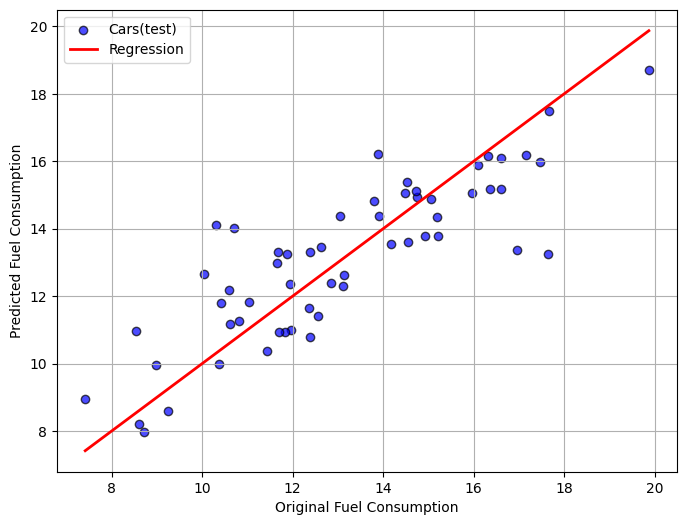

In [106]:
plt.figure(figsize=(8,6))
plt.scatter(
    y_test, y_pred,
    color='blue',
    alpha=0.7,
    edgecolors='k',
    label='Cars(test)'
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linewidth=2,
    label='Regression'
)
plt.title = 'Fuel consumption'
plt.legend()
plt.xlabel('Original Fuel Consumption')
plt.ylabel('Predicted Fuel Consumption')
plt.grid(True)
plt.show()